In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#read dataset as pandas dataframe

cardio_df = pd.read_csv('cardio_data.csv')
cardio_df.head()

,id,Age,Gender,Height,Weight,Systolic,Diastolic,Cholesterol,Glucose,Smoke,Alcohol,Physical_Activity,CVD
0,0,18393,2,168,62.0,110,80,normal,normal,0,no,yes,0
1,1,20228,1,156,85.0,140,90,very high,normal,0,no,yes,1
2,2,18857,1,165,64.0,130,70,very high,normal,0,no,no,1
3,3,17623,2,169,82.0,150,100,normal,normal,0,no,yes,1
4,4,17474,1,156,56.0,100,60,normal,normal,0,no,no,0


In [3]:
#checking for missing values

cardio_df.isna().sum()

#cleaning data columns

cardio_df['Gender'] = cardio_df['Gender'].replace({1:'Female', 2:'Male'})
cardio_df['Smoke'] = cardio_df['Smoke'].replace({0:'No', 1:'Yes'})
cardio_df['CVD'] = cardio_df['CVD'].replace({0:'No', 1:'Yes'})

cardio_df['Age'] = np.round(cardio_df['Age'] / 365).astype('int')
cardio_df = cardio_df.drop(['id'], axis=1)

#check for negative values in systolic and diastolic columns and convert to positive values
cardio_df['Systolic'] = cardio_df['Systolic'].astype('str')
cardio_df['Systolic'] = cardio_df['Systolic'].str.strip('-')
cardio_df['Systolic'] = cardio_df['Systolic'].astype('int')

cardio_df['Diastolic'] = cardio_df['Diastolic'].astype('str')
cardio_df['Diastolic'] = cardio_df['Diastolic'].str.strip('-')
cardio_df['Diastolic'] = cardio_df['Diastolic'].astype('int')

#handling outliers
cardio_df['Systolic'] = cardio_df['Systolic'].apply(lambda x: 200 if x > 200 else x)
cardio_df[cardio_df['Systolic'] > 200]
cardio_df['Systolic'] = cardio_df['Systolic'].apply(lambda x: 60 if x < 60 else x)
cardio_df[cardio_df['Systolic'] < 60]

cardio_df['Diastolic'] = cardio_df['Diastolic'].apply(lambda x: 50 if x < 50 else x)
cardio_df[cardio_df['Diastolic'] < 50]
cardio_df['Diastolic'] = cardio_df['Diastolic'].apply(lambda x: 180 if x > 180 else x)
cardio_df[cardio_df['Diastolic'] > 180]

cardio_df.head()



,Age,Gender,Height,Weight,Systolic,Diastolic,Cholesterol,Glucose,Smoke,Alcohol,Physical_Activity,CVD
0,50,Male,168,62.0,110,80,normal,normal,No,no,yes,No
1,55,Female,156,85.0,140,90,very high,normal,No,no,yes,Yes
2,52,Female,165,64.0,130,70,very high,normal,No,no,no,Yes
3,48,Male,169,82.0,150,100,normal,normal,No,no,yes,Yes
4,48,Female,156,56.0,100,60,normal,normal,No,no,no,No


In [4]:
#Random five data points

cardio_df.sample(n=5)

,Age,Gender,Height,Weight,Systolic,Diastolic,Cholesterol,Glucose,Smoke,Alcohol,Physical_Activity,CVD
39093,42,Female,147,70.0,140,90,normal,normal,No,no,yes,Yes
14550,45,Female,178,78.0,120,80,normal,normal,No,no,yes,No
55084,42,Female,165,65.0,110,70,normal,normal,No,no,no,No
67060,48,Male,170,107.0,130,90,high,normal,Yes,yes,yes,No
49539,62,Male,168,56.0,140,90,normal,high,No,no,yes,Yes


In [5]:
#Shape of data
print("shape of data :", cardio_df.shape)

#Size of data set
print("size of dataset :", cardio_df.size)

shape of data : (70000, 12)
size of dataset : 840000


In [6]:
#Data Types
cardio_df.dtypes

Age                    int64
Gender                object
Height                 int64
Weight               float64
Systolic               int64
Diastolic              int64
Cholesterol           object
Glucose               object
Smoke                 object
Alcohol               object
Physical_Activity     object
CVD                   object
dtype: object

In [7]:
#Statistical Description of categorical columns
cardio_df.describe()

,Age,Height,Weight,Systolic,Diastolic
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,53.338686,164.359229,74.205690,126.854386,82.703229
std,6.765294,8.210126,14.395757,17.419102,14.960110
min,30.000000,55.000000,10.000000,60.000000,50.000000
25%,48.000000,159.000000,65.000000,120.000000,80.000000
50%,54.000000,165.000000,72.000000,120.000000,80.000000
75%,58.000000,170.000000,82.000000,140.000000,90.000000
max,65.000000,250.000000,200.000000,200.000000,180.000000


In [8]:
#statistical description of numerical columns
cardio_df.describe(exclude=[np.number])

,Gender,Cholesterol,Glucose,Smoke,Alcohol,Physical_Activity,CVD
count,70000,70000,70000,70000,70000,70000,70000
unique,2,3,3,2,2,2,2
top,Female,normal,normal,No,no,yes,No
freq,45530,52385,59479,63831,66236,56261,35021


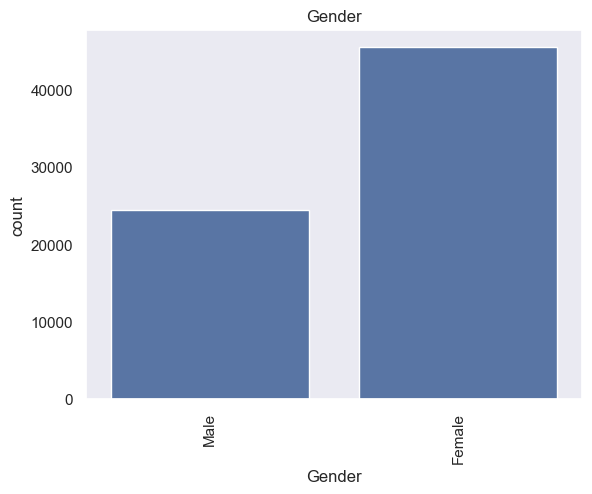

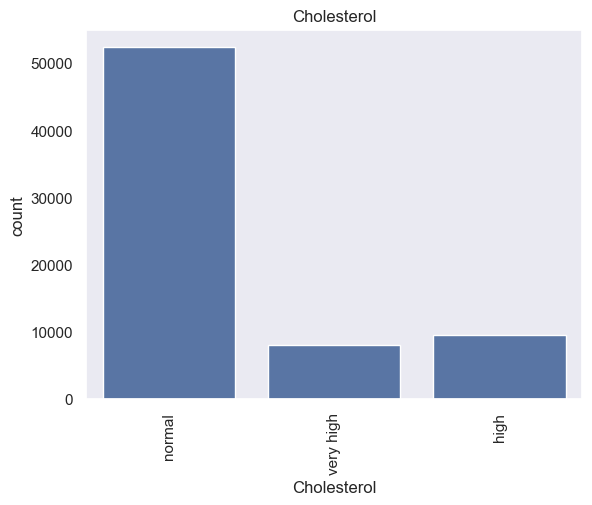

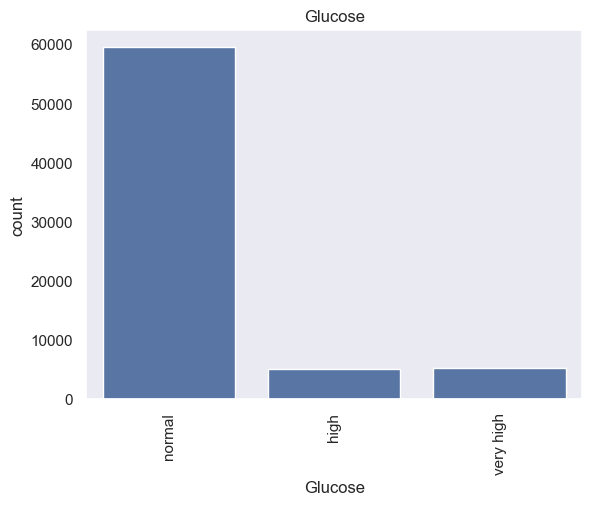

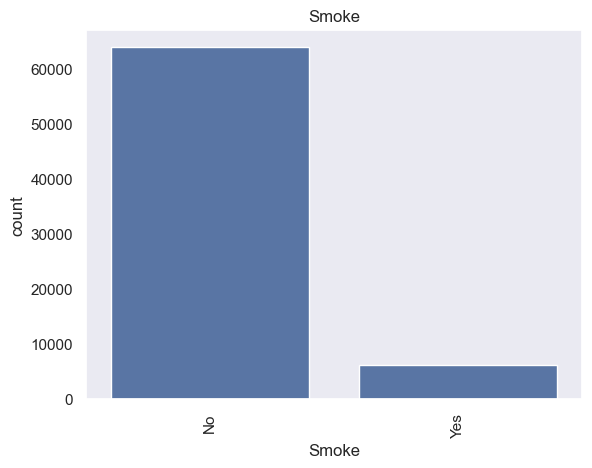

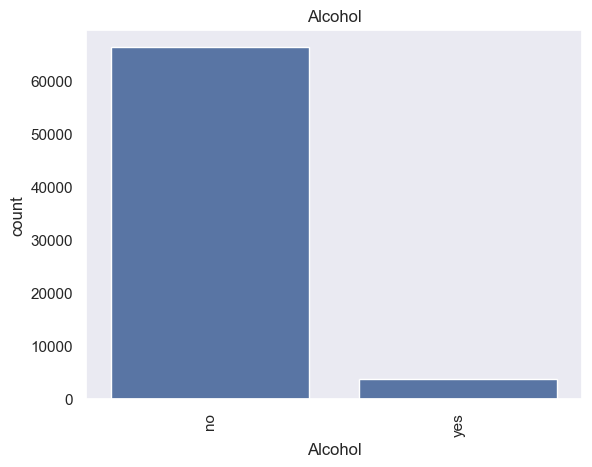

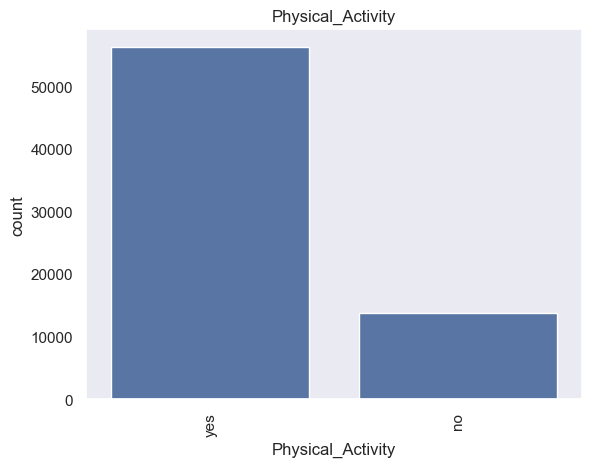

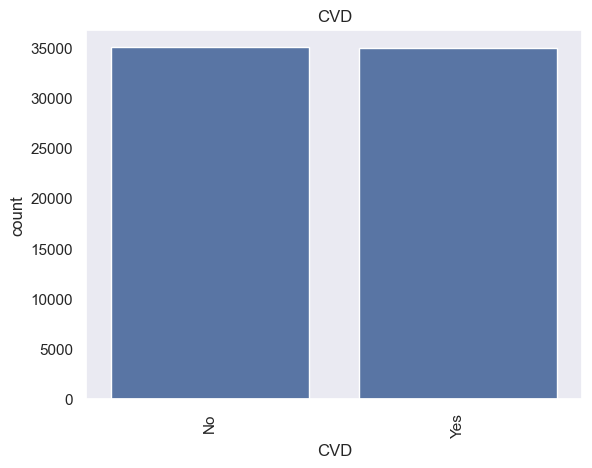

In [9]:
#data visualization
columns = ['Gender', 'Cholesterol', 'Glucose',
           'Smoke', 'Alcohol', 'Physical_Activity', 'CVD']

sns.set(style='dark',font_scale=1)
#sns.set_palette('husl',3)

def plot_cat_count():
    for c in columns:
        sns.countplot(x=c, data=cardio_df)
        plt.title(c)
        plt.xticks(rotation=90)
        plt.show()

plot_cat_count()

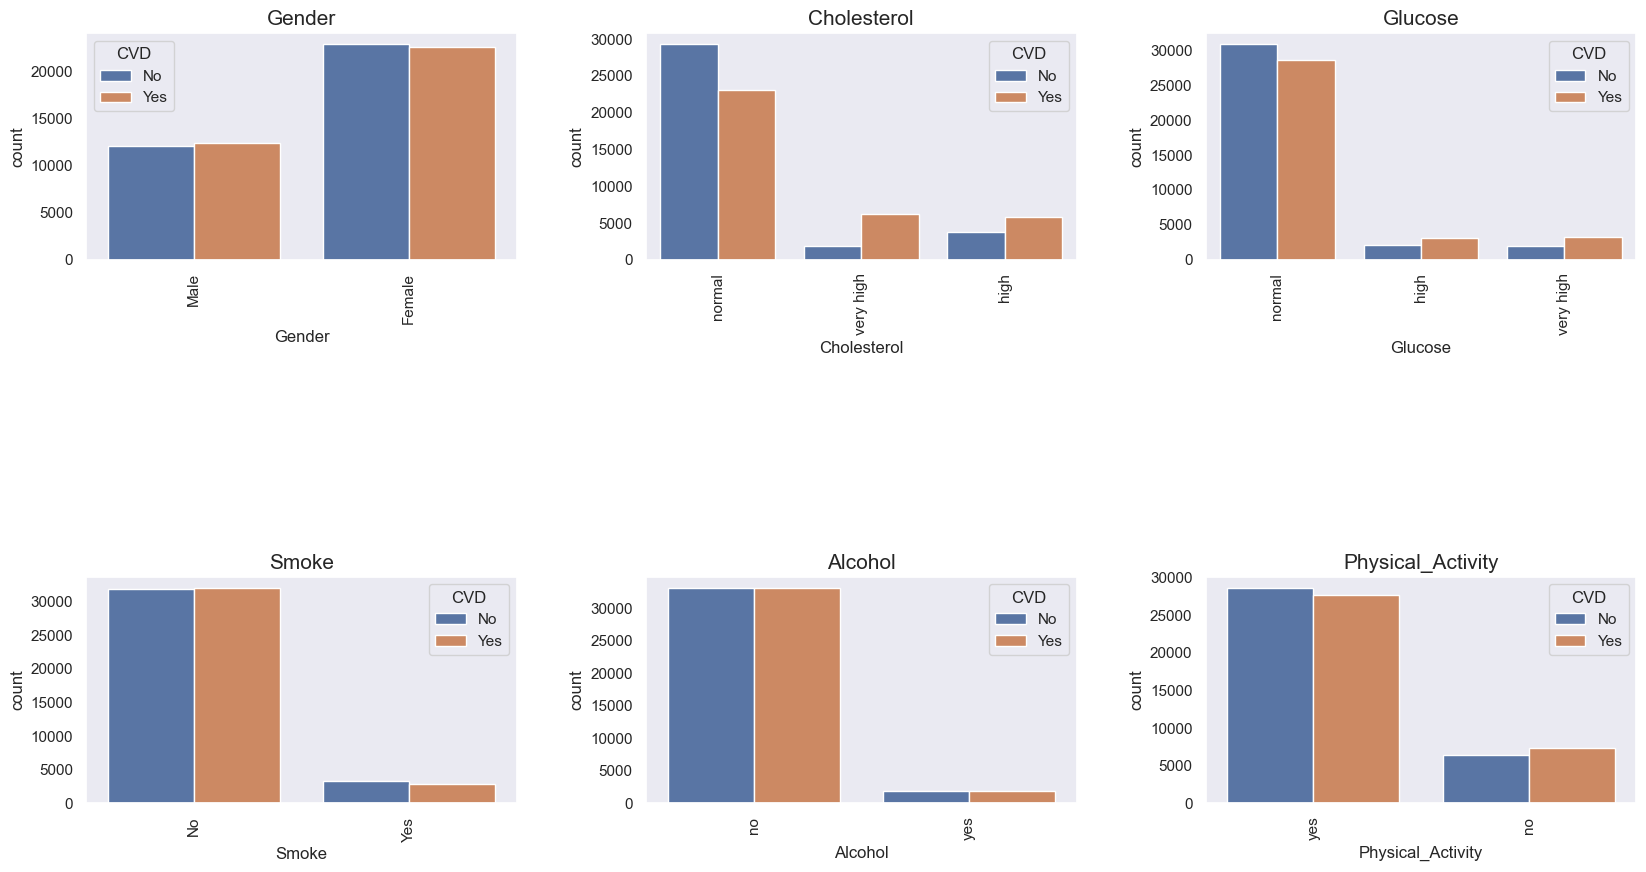

In [10]:
#visualize the information above for easy understanding
#value counting the categorical columns

cols = ['Gender', 'Cholesterol', 'Glucose',
        'Smoke', 'Alcohol', 'Physical_Activity']
# plot data distribution
fig, axs = plt.subplots(2,3, figsize=(20, 10))
axs = axs.flatten()
#sns.set_style('white')
#sns.set_palette("PuRd")

for i, var in enumerate(cols):
    sns.countplot(x=var, ax=axs[i], data=cardio_df, hue='CVD')
    axs[i].set_title(var, fontsize=15)
    axs[i].tick_params(axis='x', labelrotation=90)

plt.subplots_adjust(hspace=1.4, wspace=0.3)
plt.savefig('cvd_by_category.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
#print all column name
cardio_df.columns

Index(['Age', 'Gender', 'Height', 'Weight', 'Systolic', 'Diastolic',
       'Cholesterol', 'Glucose', 'Smoke', 'Alcohol', 'Physical_Activity',
       'CVD'],
      dtype='object')

In [12]:
#preprocessing data for modelling
cardio_data = pd.get_dummies(cardio_df, drop_first=True)

In [13]:
cardio_data.head()

,Age,Height,Weight,Systolic,Diastolic,Gender_Male,Cholesterol_normal,Cholesterol_very high,Glucose_normal,Glucose_very high,Smoke_Yes,Alcohol_yes,Physical_Activity_yes,CVD_Yes
0,50,168,62.0,110,80,True,True,False,True,False,False,False,True,False
1,55,156,85.0,140,90,False,False,True,True,False,False,False,True,True
2,52,165,64.0,130,70,False,False,True,True,False,False,False,False,True
3,48,169,82.0,150,100,True,True,False,True,False,False,False,True,True
4,48,156,56.0,100,60,False,True,False,True,False,False,False,False,False


In [14]:
cardio_data.dtypes

Age                        int64
Height                     int64
Weight                   float64
Systolic                   int64
Diastolic                  int64
Gender_Male                 bool
Cholesterol_normal          bool
Cholesterol_very high       bool
Glucose_normal              bool
Glucose_very high           bool
Smoke_Yes                   bool
Alcohol_yes                 bool
Physical_Activity_yes       bool
CVD_Yes                     bool
dtype: object

In [15]:
#check for correlation to avoid overfitting of model
df = cardio_data.corr()
df[['CVD_Yes']].sort_values(by='CVD_Yes', ascending=False)

,CVD_Yes
CVD_Yes,1.000000
Systolic,0.419756
Diastolic,0.275681
Age,0.237749
Cholesterol_very high,0.191798
Weight,0.181660
Glucose_very high,0.070241
Gender_Male,0.008109
Alcohol_yes,-0.007330
Height,-0.010821


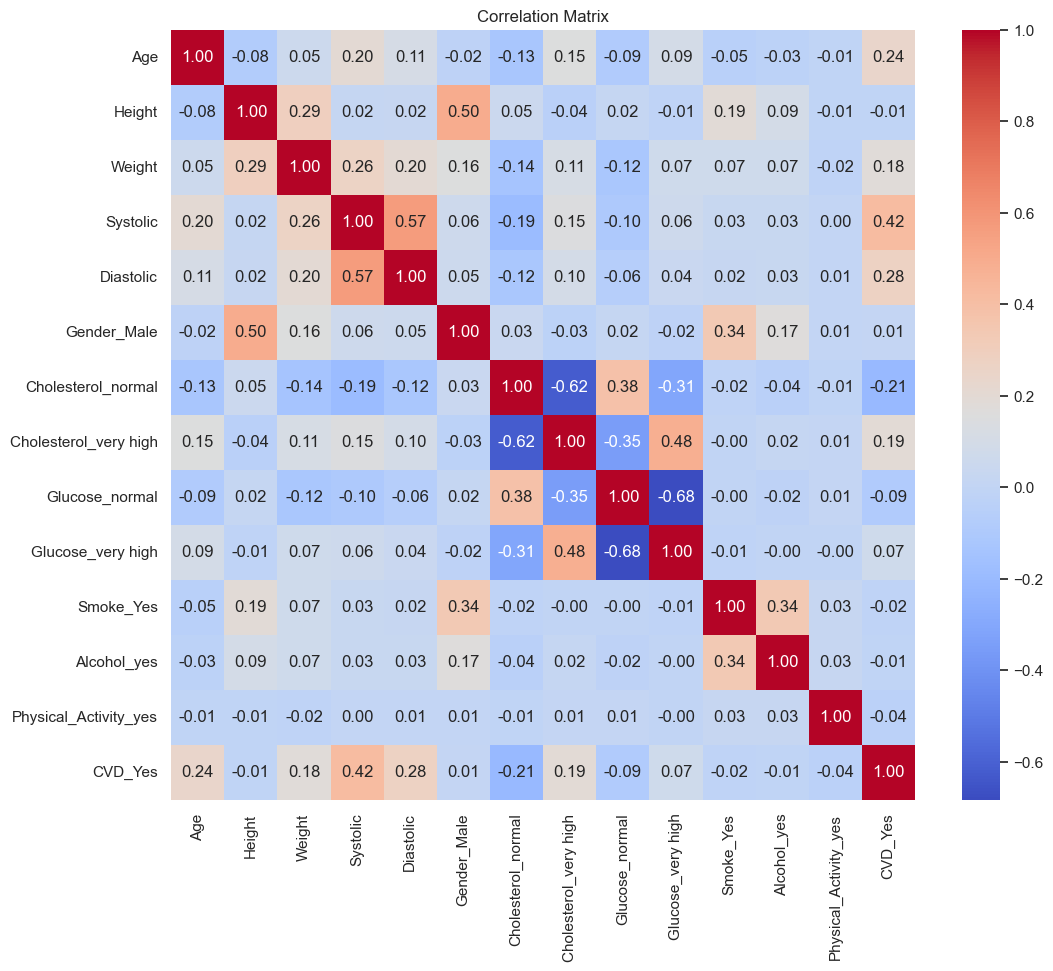

In [16]:
plt.figure(figsize=(12, 10))
sns.heatmap(cardio_data.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [17]:
#preprocessing categorical columns using pd get dummies
X = cardio_data.drop(['CVD_Yes'], axis=1)
X = X.values

y = cardio_data['CVD_Yes'].values

print('X shape:', X.shape)

print('y shape:', y.shape)

X shape: (70000, 13)
y shape: (70000,)


In [18]:
#checking if the data is balance
cardio_data['CVD_Yes'].value_counts()

CVD_Yes
False    35021
True     34979
Name: count, dtype: int64

In [19]:
#!pip install lightgbm
from lightgbm import LGBMClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, accuracy_score

In [20]:
#train test split features and target variables
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,stratify=y,random_state=23)

In [21]:
# Define the model
lgb_model = LGBMClassifier()

# Fit the model
lgb_model.fit(X_train, y_train)

[LightGBM] [Info] Number of positive: 24485, number of negative: 24515
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001538 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 436
[LightGBM] [Info] Number of data points in the train set: 49000, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499694 -> initscore=-0.001224
[LightGBM] [Info] Start training from score -0.001224


LGBMClassifier()

In [22]:
test_predictions = lgb_model.predict(X_test)
train_prediction = lgb_model.predict(X_train)
#check model accuracy, precision and recall score
acc_scoreX = accuracy_score(y_train, train_prediction)
print('Training_accuracy_score :', acc_scoreX)
acc_score = accuracy_score(y_test, test_predictions)
print('Testing_accuracy_score :', acc_score)
pre_score = precision_score(y_test, test_predictions)
print('precision_score :', pre_score)
rec_score = recall_score(y_test, test_predictions)
print('recall_score :', rec_score)

Training_accuracy_score : 0.7506734693877551
Testing_accuracy_score : 0.7335714285714285
precision_score : 0.7539131336166683
recall_score : 0.6930627024966648


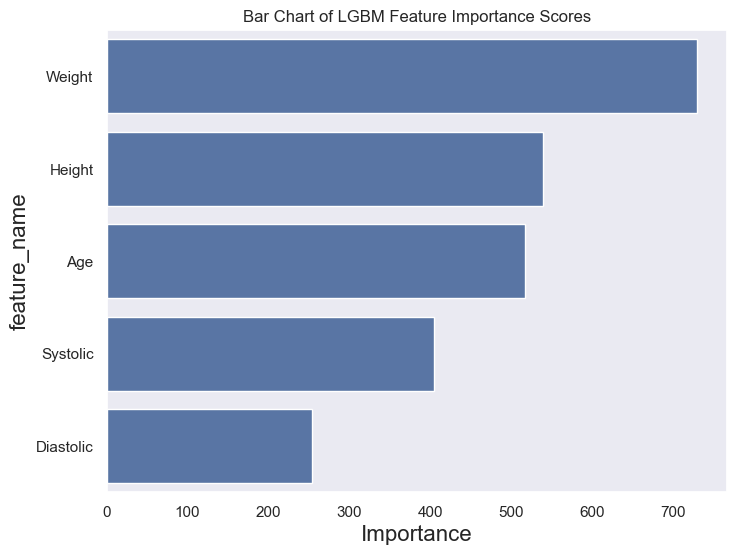

In [23]:
names = cardio_data.drop(['CVD_Yes'], axis=1).columns

# get importance
importance = lgb_model.feature_importances_

imp_df = pd.DataFrame({'feature_name':names, 'Importance':importance})
fi = imp_df.sort_values(by='Importance', ascending=False).head()

#plot feature importance
plt.figure(figsize=(8,6))
sns.barplot(data=fi, x='Importance', y='feature_name')
plt.xlabel('Importance', fontsize=16)
plt.ylabel('feature_name', fontsize=16)
plt.title('Bar Chart of LGBM Feature Importance Scores')
plt.show()

In [24]:
from sklearn.metrics import roc_auc_score

raw = pd.read_csv('cardio_data.csv')
sbp = raw['Systolic'].abs()
dbp = raw['Diastolic'].abs()
bmi = raw['Weight'] / (raw['Height'] / 100) ** 2

checks = {
    'Systolic outside 70-250 mmHg': ((sbp < 70) | (sbp > 250)).sum(),
    'Diastolic outside 40-150 mmHg': ((dbp < 40) | (dbp > 150)).sum(),
    'Diastolic >= systolic': (dbp >= sbp).sum(),
    'Height under 120 cm': (raw['Height'] < 120).sum(),
    'Weight under 30 kg': (raw['Weight'] < 30).sum(),
    'BMI under 13 or over 60': ((bmi < 13) | (bmi > 60)).sum(),
}
print(pd.Series(checks, name='Records'))

plausible = (sbp.between(70, 250) & dbp.between(40, 150) & (dbp < sbp) &
             (raw['Height'] >= 120) & (raw['Weight'] >= 30) & bmi.between(13, 60))
print('\nRecords removed:', (~plausible).sum(), f'({(~plausible).mean():.1%})')

clean = cardio_data[plausible.values]
Xc = clean.drop(['CVD_Yes'], axis=1).values
yc = clean['CVD_Yes'].values
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.3, stratify=yc, random_state=23)

lgb_clean = LGBMClassifier(verbose=-1)
lgb_clean.fit(Xc_train, yc_train)
pred_c = lgb_clean.predict(Xc_test)
print('\nCleaned-data model')
print('Accuracy :', round(accuracy_score(yc_test, pred_c), 4))
print('Recall   :', round(recall_score(yc_test, pred_c), 4))
print('ROC AUC  :', round(roc_auc_score(yc_test, lgb_clean.predict_proba(Xc_test)[:, 1]), 4))

Systolic outside 70-250 mmHg      222
Diastolic outside 40-150 mmHg    1033
Diastolic >= systolic            1230
Height under 120 cm                52
Weight under 30 kg                  7
BMI under 13 or over 60            76
Name: Records, dtype: int64

Records removed: 1409 (2.0%)

Cleaned-data model
Accuracy : 0.7369
Recall   : 0.692
ROC AUC  : 0.8015


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_score, StratifiedKFold

models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'LightGBM': LGBMClassifier(verbose=-1),
}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({'Model': name,
                 'Accuracy': round(accuracy_score(y_test, pred), 4),
                 'Sensitivity': round(tp / (tp + fn), 4),
                 'Specificity': round(tn / (tn + fp), 4),
                 'ROC AUC': round(roc_auc_score(y_test, proba), 4),
                 'Missed CVD cases': fn})
display(pd.DataFrame(rows))

cv = cross_val_score(LGBMClassifier(verbose=-1), X, y,
                     cv=StratifiedKFold(5, shuffle=True, random_state=23), scoring='roc_auc')
print('5-fold ROC AUC:', cv.round(4), '| mean:', round(cv.mean(), 4))

,Model,Accuracy,Sensitivity,Specificity,ROC AUC,Missed CVD cases
0,Logistic Regression,0.7258,0.6735,0.778,0.7887,3426
1,LightGBM,0.7336,0.6931,0.774,0.8016,3221


5-fold ROC AUC: [0.8108 0.8042 0.7985 0.7971 0.7995] | mean: 0.802


In [26]:
y_proba = lgb_model.predict_proba(X_test)[:, 1]
rows = []
for t in [0.5, 0.4, 0.35, 0.3, 0.25]:
    p = (y_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({'Threshold': t, 'Sensitivity': round(tp / (tp + fn), 4),
                 'Specificity': round(tn / (tn + fp), 4),
                 'Missed CVD cases': fn, 'False alarms': fp})
pd.DataFrame(rows)

,Threshold,Sensitivity,Specificity,Missed CVD cases,False alarms
0,0.50,0.6931,0.7740,3221,2374
1,0.40,0.7864,0.6649,2241,3521
2,0.35,0.8356,0.5850,1725,4360
3,0.30,0.8762,0.4941,1299,5315
4,0.25,0.9289,0.3667,746,6653


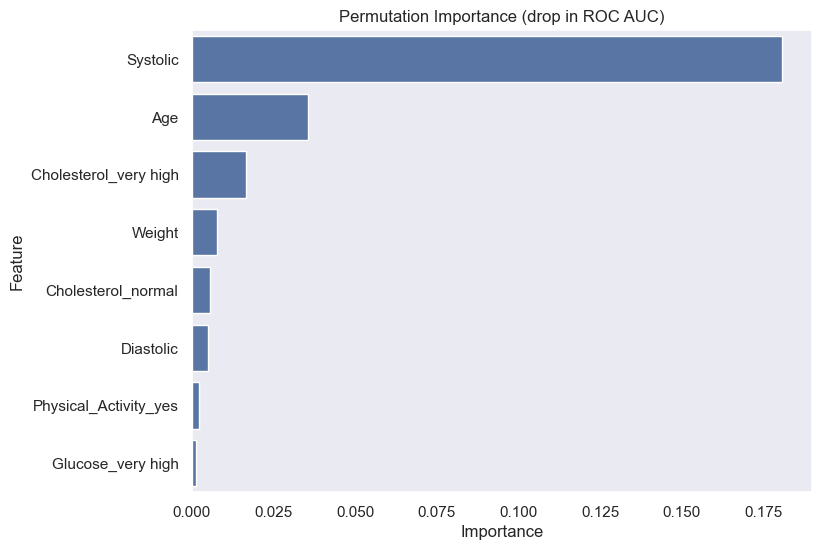

In [27]:
from sklearn.inspection import permutation_importance

names = cardio_data.drop(['CVD_Yes'], axis=1).columns
perm = permutation_importance(lgb_model, X_test, y_test, scoring='roc_auc',
                              n_repeats=5, random_state=23, n_jobs=-1)
perm_df = (pd.DataFrame({'Feature': names, 'Importance': perm.importances_mean})
           .sort_values('Importance', ascending=False))

plt.figure(figsize=(8, 6))
sns.barplot(data=perm_df.head(8), x='Importance', y='Feature')
plt.title('Permutation Importance (drop in ROC AUC)')
plt.savefig('permutation_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [28]:
s = cardio_df['Systolic']
d = cardio_df['Diastolic']
cardio_df['BP_Stage'] = np.select(
    [(s >= 140) | (d >= 90), (s >= 130) | (d >= 80), (s >= 120) & (d < 80)],
    ['Stage 2', 'Stage 1', 'Elevated'], 'Normal')

bp = pd.crosstab(cardio_df['BP_Stage'], cardio_df['CVD'], normalize='index').mul(100).round(1)
bp['Patients'] = cardio_df['BP_Stage'].value_counts()
bp.loc[['Normal', 'Elevated', 'Stage 1', 'Stage 2']]

CVD,No,Yes,Patients
BP_Stage,,,
Normal,77.8,22.2,9608
Elevated,67.6,32.4,3125
Stage 1,61.5,38.5,32561
Stage 2,21.8,78.2,24706


Brier score: 0.1803


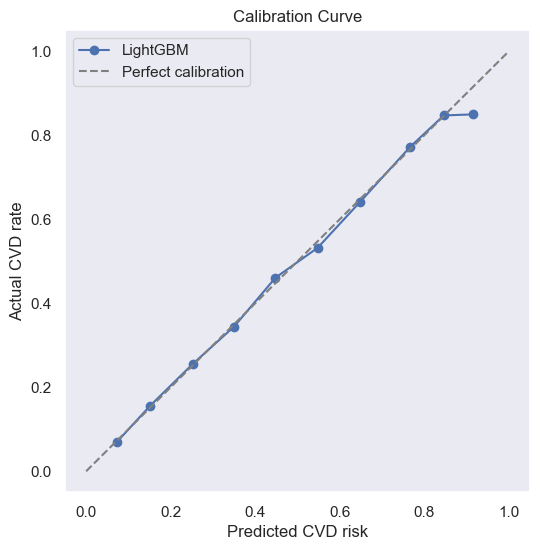

In [29]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

y_proba = lgb_model.predict_proba(X_test)[:, 1]
print('Brier score:', round(brier_score_loss(y_test, y_proba), 4))

frac_pos, mean_pred = calibration_curve(y_test, y_proba, n_bins=10)
plt.figure(figsize=(6, 6))
plt.plot(mean_pred, frac_pos, marker='o', label='LightGBM')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect calibration')
plt.xlabel('Predicted CVD risk')
plt.ylabel('Actual CVD rate')
plt.title('Calibration Curve')
plt.legend()
plt.savefig('calibration_curve.png', dpi=150, bbox_inches='tight')
plt.show()